# 01 – Exploratory Data Analysis

**Dataset:** [Brain Tumor MRI Dataset](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset):
7,200 MRI slices, 4 classes (glioma, meningioma, notumor, pituitary).

**Goal:** understand the data before modeling:
class balance, image sizes and formats, visual characteristics, and possible biases
(duplicates, source differences) that could inflate results or cause shortcut learning.

Import the dependencies

In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

DATA_DIR = Path("../data/raw")
SPLITS = ["Training", "Testing"]
CLASSES = sorted(p.name for p in (DATA_DIR / "Training").iterdir() if p.is_dir())

random.seed(42)
print(CLASSES)

['glioma', 'meningioma', 'notumor', 'pituitary']


In [2]:
# table with all the images
rows = []
for split in SPLITS:
    for cls in CLASSES:
        for f in (DATA_DIR / split / cls).iterdir():
            rows.append({"split": split, "label": cls, "path": f})

df = pd.DataFrame(rows)
print(len(df))
df.head()

7200


,split,label,path
0,Training,glioma,..\data\raw\Training\glioma\Tr-gl_1.jpg
1,Training,glioma,..\data\raw\Training\glioma\Tr-gl_10.jpg
2,Training,glioma,..\data\raw\Training\glioma\Tr-gl_100.jpg
3,Training,glioma,..\data\raw\Training\glioma\Tr-gl_1000.jpg
4,Training,glioma,..\data\raw\Training\glioma\Tr-gl_1001.jpg


In [3]:
# class distribution
pd.crosstab(df["label"], df["split"], margins = True)

split,Testing,Training,All
label,,,
glioma,400,1400,1800
meningioma,400,1400,1800
notumor,400,1400,1800
pituitary,400,1400,1800
All,1600,5600,7200


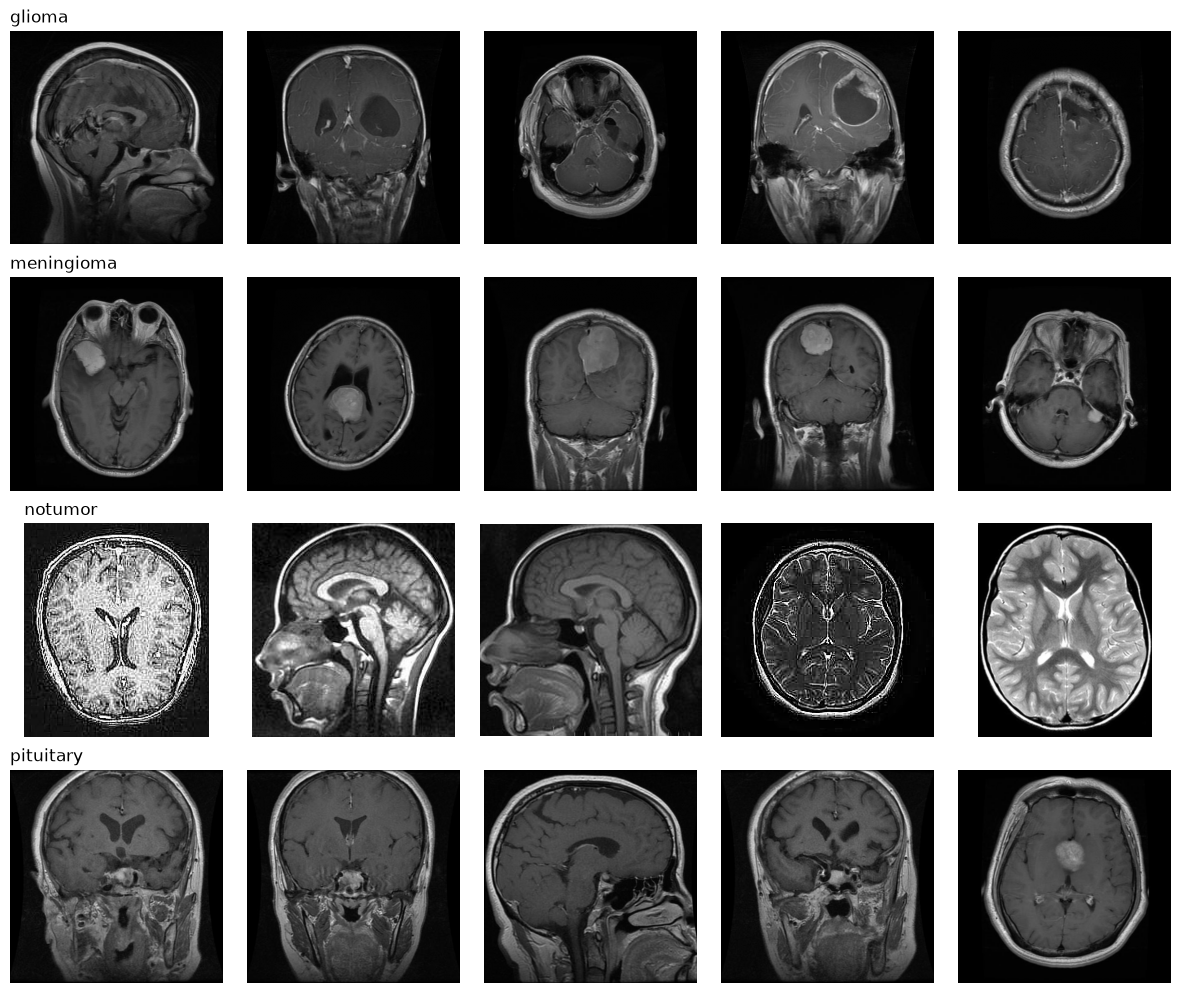

In [4]:
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(12,10))

for i, cls in enumerate(CLASSES):
    sample = df[(df["split"] == "Training") & (df["label"] == cls)].sample(5, random_state=42)
    for j, path in enumerate(sample["path"]):
        img = Image.open(path)
        axes[i,j].imshow(img, cmap = "gray")
        axes[i,j].axis("off")
    axes[i,0].set_title(cls, loc="left")

plt.tight_layout()
plt.show()

### Observations: visual inspection

- **Mixed planes** (axial, coronal, sagittal) in all classes, but not evenly distributed.
  Example: pituitary often appears in coronal view.
  → Risk of *shortcut learning* (the model learns the plane instead of the tumor).
  To be checked with Grad-CAM.
- **notumor looks different**: higher contrast, some T2-weighted sequences
  (bright cerebrospinal fluid), different aspect ratios. Likely a different source dataset.
  → Risk of a style-based shortcut. To be verified numerically (cells 5–6).
- **No text overlays**; **black borders** of varying thickness.
- **Radiological cues**: glioma = intra-axial (inside brain tissue), irregular, often with a necrotic core;
  meningioma = peripheral, round, well-defined; pituitary = base of the brain, midline.

In [5]:
def img_info(path):
    with Image.open(path) as img:
        return img.width, img.height, img.mode

info = [img_info(p) for p in df["path"]]
df[["width", "height", "mode"]] = pd.DataFrame(info, index = df.index)

print(df["mode"].value_counts(), "\n")
df.groupby("label")[["width", "height"]].agg(["min", "median", "max"])

mode
RGB     4129
L       3067
RGBA       3
P          1
Name: count, dtype: int64 



width              height             
             min median   max    min median   max
label                                            
glioma       175  512.0   640    167  512.0   665
meningioma   174  512.0  1275    195  512.0  1427
notumor      150  228.0  1375    168  243.0  1446
pituitary    201  512.0  1365    202  512.0  1365

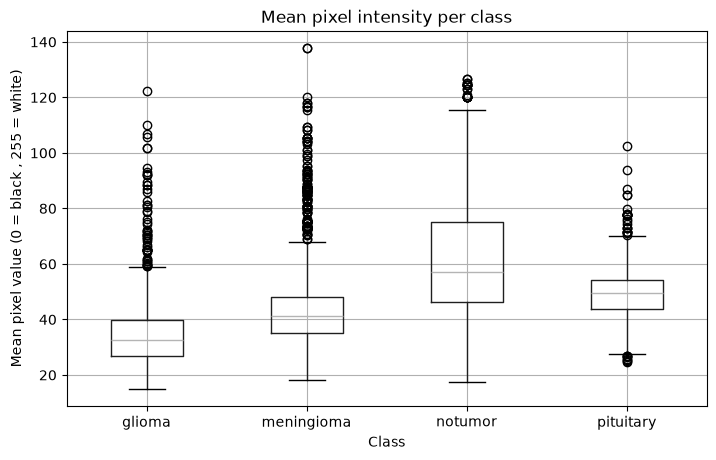

In [6]:
def mean_intensity(path):
    with Image.open(path) as img:
        return np.asarray(img.convert("L"), dtype = np.float32).mean()

df["mean_px"] = [mean_intensity(p) for p in df["path"]]

df.boxplot(column="mean_px", by="label", figsize=(8, 5))
plt.suptitle("")
plt.title("Mean pixel intensity per class")
plt.xlabel("Class")
plt.ylabel("Mean pixel value (0 = black , 255 = white)")
plt.show()

### Observations: image format, size and intensity

- **Mixed color modes**: RGB (4129), L (3067), RGBA (3), P (1). MRI is grayscale by nature.
  → Convert everything to RGB (3 identical channels) to match ImageNet-pretrained models.
- **notumor images are much smaller** (median ~228×243 vs 512×512 for other classes),
  sizes range from 150 to 1446 px, aspect ratios vary.
  → Another source fingerprint: resizing affects classes differently (sharpness artifacts).
- **Mean intensity differs across classes** (medians: glioma ~32, meningioma ~41,
  pituitary ~49, notumor ~57); notumor is the brightest and most heterogeneous.
  → Brightness alone carries class information: a possible shortcut.
  Part of it may come from framing (less black border in smaller images).
- **The test set shares the same bias**, so test accuracy cannot reveal this shortcut.
  → Use Grad-CAM to check what the model looks at; document as a limitation.

In [7]:
import imagehash

def phash(path):
    with Image.open(path) as img:
        return str(imagehash.phash(img.convert("L")))

df["phash"] = [phash(p) for p in df["path"]]
df["phash"].head()

0    d01f2b693cb46d70
1    c09e6b8d2f8b6c2c
2    c03f2f3d36e43292
3    c0967e493e8e2d6c
4    93cf6c906166b63c
Name: phash, dtype: str

In [8]:
n_unique = df["phash"].nunique()
print(f"Unique hashes: {n_unique} of {len(df)} images")

train_hashes = set(df.loc[df["split"] == "Training", "phash"])
test_df = df[df["split"] == "Testing"]
leak = test_df[test_df["phash"].isin(train_hashes)]
print(f"Test images with a duplicate in Training: {len(leak)} ({len(leak) / len(test_df):.1%})")

labels_per_hash = df.groupby("phash")["label"].nunique()
print(f"Hashes with conflicting labels: {(labels_per_hash > 1).sum()}")

Unique hashes: 6212 of 7200 images
Test images with a duplicate in Training: 370 (23.1%)
Hashes with conflicting labels: 1


In [9]:
print("Leaked test images per class:")
print(leak["label"].value_counts(), "\n")

df["is_dup"] = df.duplicated("phash", keep="first")
pd.crosstab(df["label"], df["split"], values=df["is_dup"], aggfunc="sum", margins=True)

Leaked test images per class:
label
notumor       257
meningioma    105
glioma          6
pituitary       2
Name: count, dtype: int64 



split,Testing,Training,All
label,,,
glioma,23,3,26
meningioma,107,26,133
notumor,288,489,777
pituitary,2,50,52
All,420,568,988


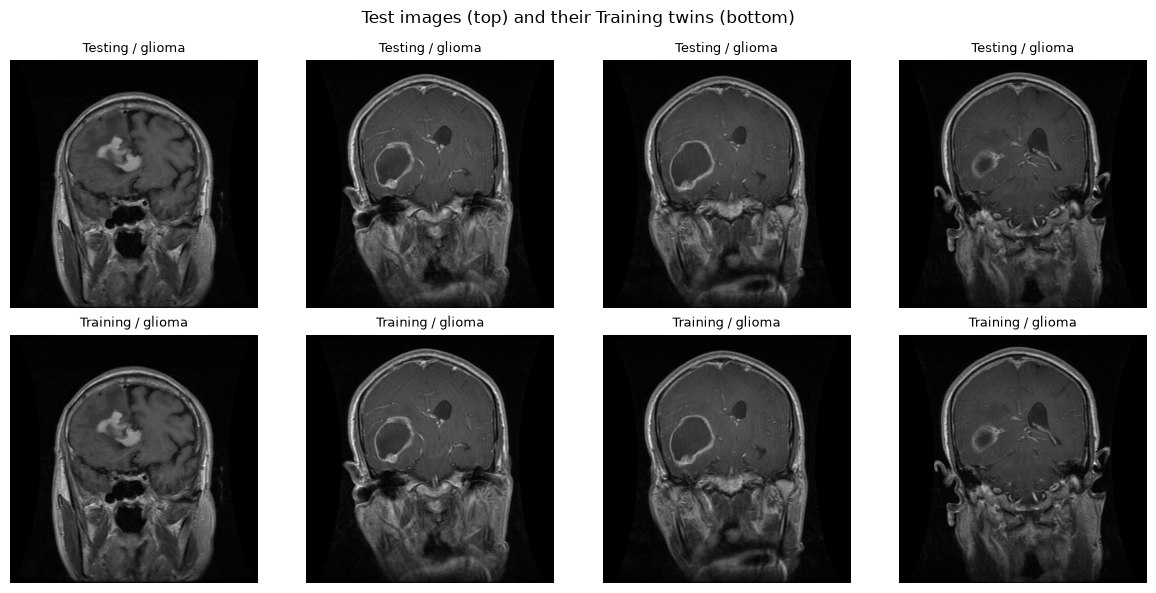

In [10]:
pairs = leak.head(4)
fig, axes = plt.subplots(2, len(pairs), figsize=(12, 6))

for j, (_, row) in enumerate(pairs.iterrows()):
    twin = df[(df["split"] == "Training") & (df["phash"] == row["phash"])].iloc[0]
    for i, r in enumerate([row, twin]):
        axes[i, j].imshow(Image.open(r["path"]), cmap="gray")
        axes[i, j].set_title(f'{r["split"]} / {r["label"]}', fontsize=9)
        axes[i, j].axis("off")

plt.suptitle("Test images (top) and their Training twins (bottom)")
plt.tight_layout()
plt.show()

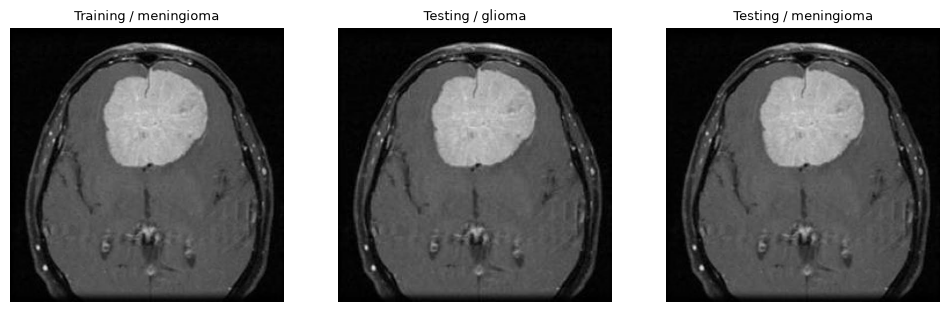

,split,label,path
2199,Training,meningioma,..\data\raw\Training\meningioma\Tr-me_458.jpg
5965,Testing,glioma,..\data\raw\Testing\glioma\Te-gl_68.jpg
6396,Testing,meningioma,..\data\raw\Testing\meningioma\Te-me_96.jpg


In [11]:
conflict_hashes = labels_per_hash[labels_per_hash > 1].index
conflicts = df[df["phash"].isin(conflict_hashes)]

fig, axes = plt.subplots(1, len(conflicts), figsize=(4 * len(conflicts), 4))
for ax, (_, r) in zip(axes, conflicts.iterrows()):
    ax.imshow(Image.open(r["path"]), cmap="gray")
    ax.set_title(f'{r["split"]} / {r["label"]}', fontsize=9)
    ax.axis("off")
plt.show()

conflicts[["split", "label", "path"]]

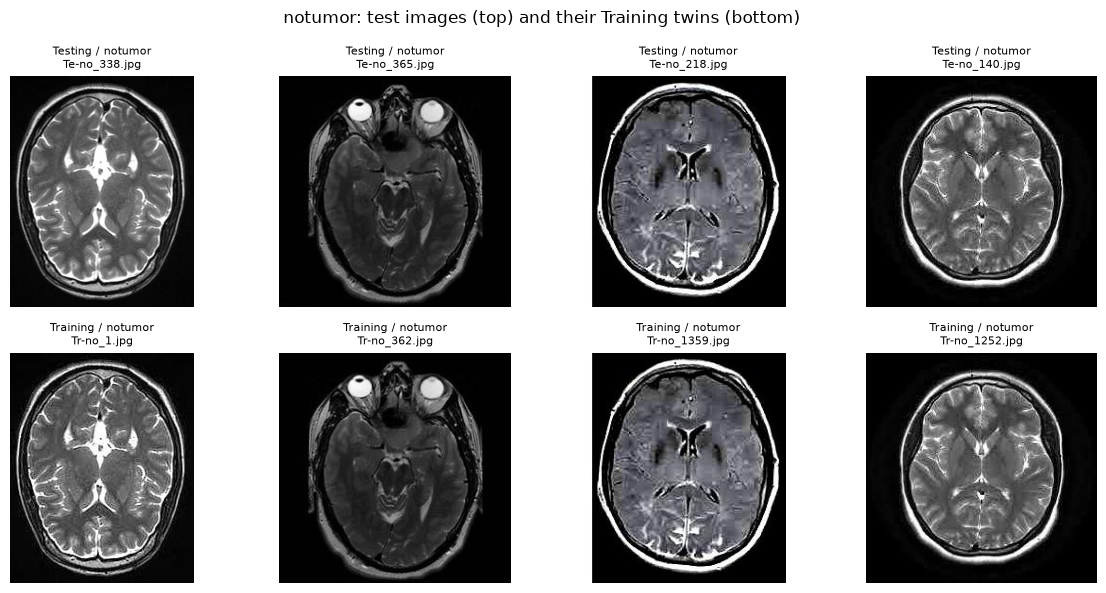

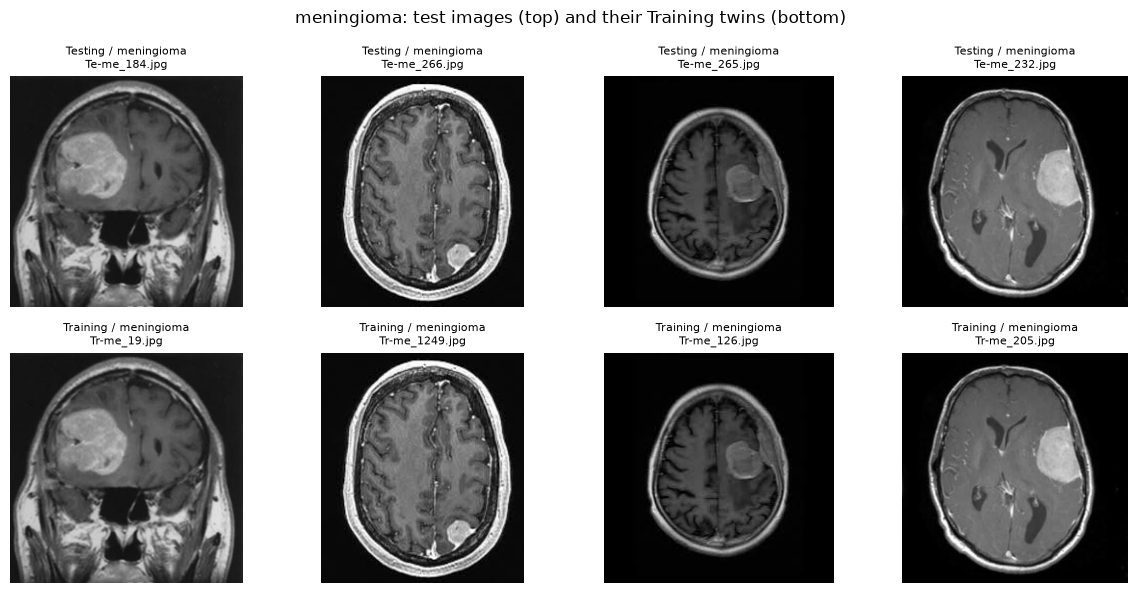

In [12]:
def show_leak_pairs(label, n=4):
    pairs = leak[leak["label"] == label].sample(n, random_state=42)
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6))

    for j, (_, row) in enumerate(pairs.iterrows()):
        twin = df[(df["split"] == "Training") & (df["phash"] == row["phash"])].iloc[0]
        for i, r in enumerate([row, twin]):
            axes[i, j].imshow(Image.open(r["path"]), cmap="gray")
            axes[i, j].set_title(f'{r["split"]} / {r["label"]}\n{r["path"].name}', fontsize=8)
            axes[i, j].axis("off")

    plt.suptitle(f"{label}: test images (top) and their Training twins (bottom)")
    plt.tight_layout()
    plt.show()

show_leak_pairs("notumor")
show_leak_pairs("meningioma")

### Observations: duplicates and leakage

- **988 redundant copies** (13.7% of the dataset): 6212 unique images out of 7200.
- **370 test images (23.1%) have an identical twin in Training** → data leakage;
  any accuracy on the official split is inflated.
- Copies are concentrated in **notumor** (777 copies, ~43% of the class; 489 inside Training)
  and **meningioma** (133). Glioma and pituitary are almost clean.
- Duplicates also exist **within** the test set.
- **1 label conflict**: `Te-gl_68.jpg` is labeled glioma but is a textbook meningioma
  (round, bright, well-defined, extra-axial); its twins are labeled meningioma. → Drop all 3.
- ⚠️ After deduplication **classes will no longer be balanced** (notumor ~1000 vs ~1800):
  the "accuracy is valid" conclusion must be revisited.

## Dataset cleaning & re-split

The official Training/Testing split is contaminated (23.1% of test images leak from Training).
**Strategy:** pool all images, drop label conflicts, keep one copy per perceptual hash,
then create a new stratified **70 / 15 / 15** train/val/test split.

**Known limitation:** no patient IDs are available, so different slices of the same patient
may still end up in different splits (patient-level leakage cannot be ruled out).

split       Testing  Training  All
label                             
glioma            0         0    0
meningioma      103       100  203
notumor           0         0    0
pituitary         0         0    0
All             103       100  203 



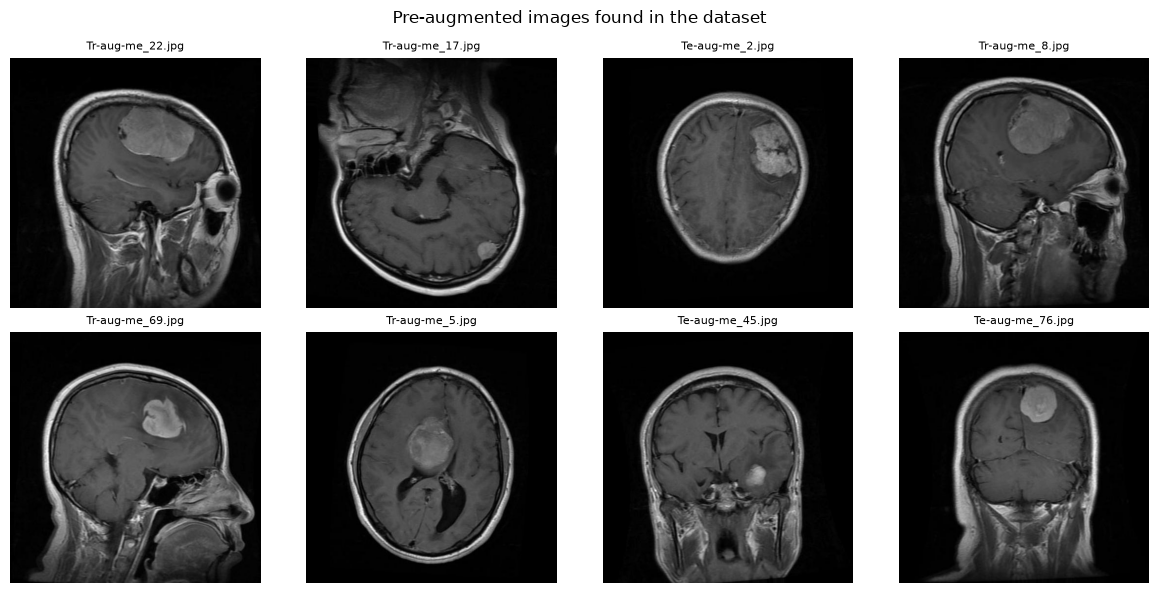

In [13]:
df["is_aug"] = df["path"].apply(lambda p: "-aug-" in p.name)

print(pd.crosstab(df["label"], df["split"], values=df["is_aug"], aggfunc="sum", margins=True), "\n")

aug_sample = df[df["is_aug"]].sample(8, random_state=42)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, path in zip(axes.flat, aug_sample["path"]):
    ax.imshow(Image.open(path), cmap="gray")
    ax.set_title(path.name, fontsize=8)
    ax.axis("off")
plt.suptitle("Pre-augmented images found in the dataset")
plt.tight_layout()
plt.show()

In [14]:
conflict_mask = df["phash"].isin(conflict_hashes)

clean = (
    df[~conflict_mask & ~df["is_aug"]]
    .drop_duplicates("phash", keep="first")
    .reset_index(drop=True)
)

print(f"Removed {len(df) - len(clean)} images, {len(clean)} remaining\n")
clean["label"].value_counts()

Removed 1180 images, 6020 remaining



label
glioma        1774
pituitary     1748
meningioma    1475
notumor       1023
Name: count, dtype: int64

In [15]:
from sklearn.model_selection import train_test_split

train_set, temp_set = train_test_split(
    clean, test_size=0.30, stratify=clean["label"], random_state=42
)
val_set, test_set = train_test_split(
    temp_set, test_size=0.50, stratify=temp_set["label"], random_state=42
)

splits = {"train": train_set, "val": val_set, "test": test_set}
for name, part in splits.items():
    print(f"{name:>5}: {len(part)} images")

pd.DataFrame({name: part["label"].value_counts(normalize=True) for name, part in splits.items()}).round(3)

train: 4214 images
  val: 903 images
 test: 903 images


,train,val,test
label,,,
glioma,0.295,0.295,0.295
pituitary,0.290,0.290,0.290
meningioma,0.245,0.245,0.246
notumor,0.170,0.171,0.169


In [16]:
train_h, val_h, test_h = (set(s["phash"]) for s in (train_set, val_set, test_set))

assert not (train_h & test_h), "Leak between train and test!"
assert not (train_h & val_h), "Leak between train and val!"
assert not (val_h & test_h), "Leak between val and test!"
print("No overlap between splits ✓")

No overlap between splits ✓


In [17]:
SPLITS_DIR = Path("../splits")
SPLITS_DIR.mkdir(exist_ok=True)

for name, part in splits.items():
    out = part[["path", "label"]].copy()
    out["path"] = out["path"].apply(lambda p: p.relative_to("..").as_posix())
    out.to_csv(SPLITS_DIR / f"{name}.csv", index=False)

pd.read_csv(SPLITS_DIR / "train.csv").head()

,path,label
0,data/raw/Testing/pituitary/Te-pi_193.jpg,pituitary
1,data/raw/Training/notumor/Tr-no_1182.jpg,notumor
2,data/raw/Training/glioma/Tr-gl_465.jpg,glioma
3,data/raw/Training/glioma/Tr-gl_1378.jpg,glioma
4,data/raw/Training/notumor/Tr-no_807.jpg,notumor


## Conclusions & preprocessing decisions

| Finding | Decision |
|---|---|
| Mixed color modes (RGB, L, RGBA, P) | Convert all images to RGB |
| Variable sizes; notumor much smaller | Crop black borders, then resize to 224×224 |
| Class-dependent brightness (source bias) | Per-image normalization + brightness/contrast augmentation; verify with Grad-CAM |
| 988 duplicate copies, 23.1% train→test leakage | Keep one image per perceptual hash |
| 1 label conflict (`Te-gl_68.jpg`) | Drop all images in the conflicting group |
| 203 pre-augmented meningioma images | Drop all (hidden leakage, possible shortcut) |
| Official split is contaminated | New stratified 70/15/15 split, saved in `splits/` |
| After cleaning, classes are imbalanced (notumor ~17%) | Report macro-F1, per-class recall/precision and confusion matrix, not only accuracy |
| No patient IDs | Patient-level leakage cannot be excluded → documented limitation |